In [1]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


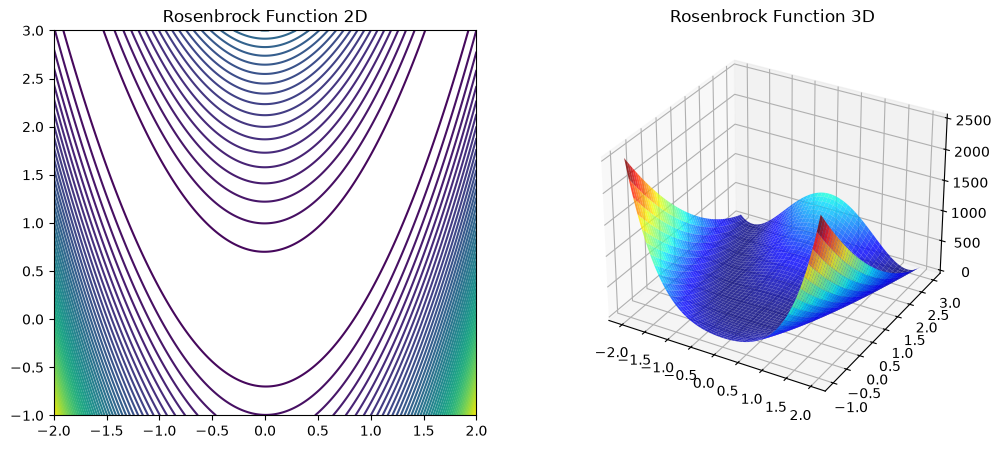

Initial guess [-1, 1.5], Result: [0.99999546 0.99999092], Value: 2.061600870824633e-11, Success: True, Iterations: 34, Time: 0.0147 sec
Initial guess [2, 2], Result: [0.99999565 0.99999129], Value: 1.8932767409827346e-11, Success: True, Iterations: 30, Time: 0.0074 sec
Initial guess [1, 0.5], Result: [0.99999545 0.99999089], Value: 2.0704689882852297e-11, Success: True, Iterations: 17, Time: 0.0038 sec


c:\Users\keert\.conda\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-1, 1.5], Solution: [1.01318097 1.02636632], Value: rosenbrock(solution), iterations: 2000, Time: 0.8619 sec


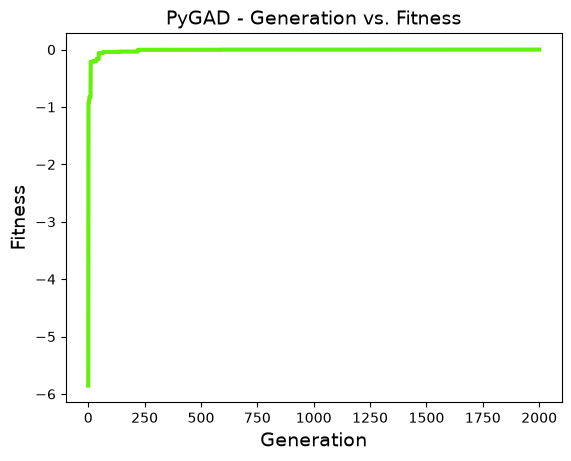

PyGAD initial guess [2, 2], Solution: [0.97256416 0.9460552 ], Value: rosenbrock(solution), iterations: 2000, Time: 1.1105 sec


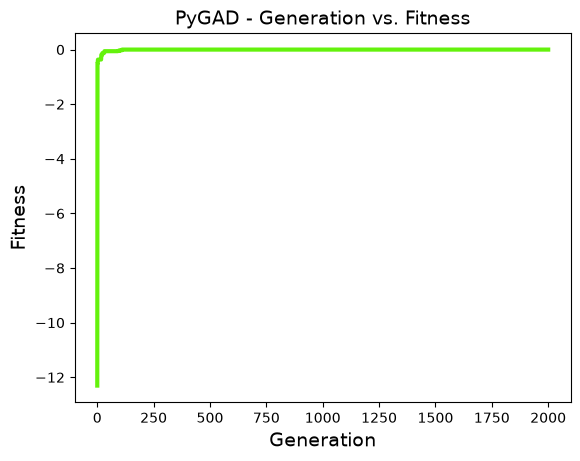

PyGAD initial guess [1, 0.5], Solution: [1.00700659 1.01406226], Value: rosenbrock(solution), iterations: 2000, Time: 0.9684 sec


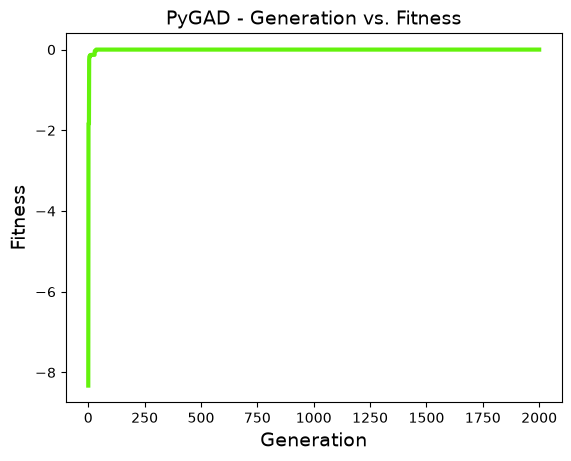

In [19]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[-1, 1.5], [2, 2], [1, 0.5]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: rosenbrock(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")
    ga_instance.plot_fitness()

# Rosenbrock Function Optimization

The Rosenbrock function is f(x,y)=(1-x)^2+100(y-x^2)^2

The objective is to minimize f(x,y).

The known global minimum is (1,1) which are the stationary points that are found analytically.

x=1, y=1; f(x,y)=0

1. SciPy Optimization

The `scipy.optimize.minimize()` function with the **BFGS** algorithm is used.

Different initial guesses such as (-1, 1.5), (2, 2), (1, 0.5) are tested. BFGS converges to approximately (x,y)=(1,1)

for the tested initial guesses, with f(x,y) approximately 0.

The 2D contour and 3D surface plots show a narrow, curved valley with the minimum at \((1,1)\).

**Conclusion:** The solution obtained is the **global minimum**. Although BFGS is a local optimization algorithm, all tested initial guesses converged to the global minimum.

2. Genetic Algorithm

The Rosenbrock function is optimized using `PyGAD`. Since PyGAD maximizes fitness, the fitness function is defined as Fitness=1/(1+f(x,y))

Different initial populations are tested.

The GA converges approximately to (x,y) =(1,1) with f(x,y)= 0


Different runs may give slightly different results because the Genetic Algorithm is stochastic.

**Conclusion:** The GA also finds the **global minimum** for the tested cases.

 3. Comparison

For the initial guesses (-1, 1.5), (2, 2), (1, 0.5) the no. of iterations taken are 34, 30, 17 and 2000, 2000, 2000 respectively for BFGS and GA.The time taken for the same initial guesses are  0.0147 sec, 0.0074 sec, 0.0038 sec and 0.8619 sec, 1.1105 sec, 0.9684 sec respectively for BFGS and GA.

| Criteria      | BFGS                | Genetic Algorithm        |
| ------------- | ------------------- | ------------------------ |
| Solution      | (1,1)               | Approximately (1,1)      |
| Minimum value | approx0             | approx0                  |
| Iterations    | Lower               | Higher                   |
| Time          | Faster              | Slower                   |
| Nature        | Deterministic/local | Stochastic/global search |
| Gradient      | Required/estimated  | Not required             |

**Overall:** BFGS is faster and more efficient for the smooth Rosenbrock function, while the Genetic Algorithm is more suitable for problems where global exploration is important or gradients are unavailable.


Initial guess [-1, 1.5], Result: [0.99999546 0.99999092], Value: 2.061600870824633e-11, Success: True, Iterations: 34, Time: 0.0113 sec
Initial guess [2, 2], Result: [0.99999565 0.99999129], Value: 1.8932767409827346e-11, Success: True, Iterations: 30, Time: 0.0084 sec
Initial guess [1, 0.5], Result: [0.99999545 0.99999089], Value: 2.0704689882852297e-11, Success: True, Iterations: 17, Time: 0.0041 sec


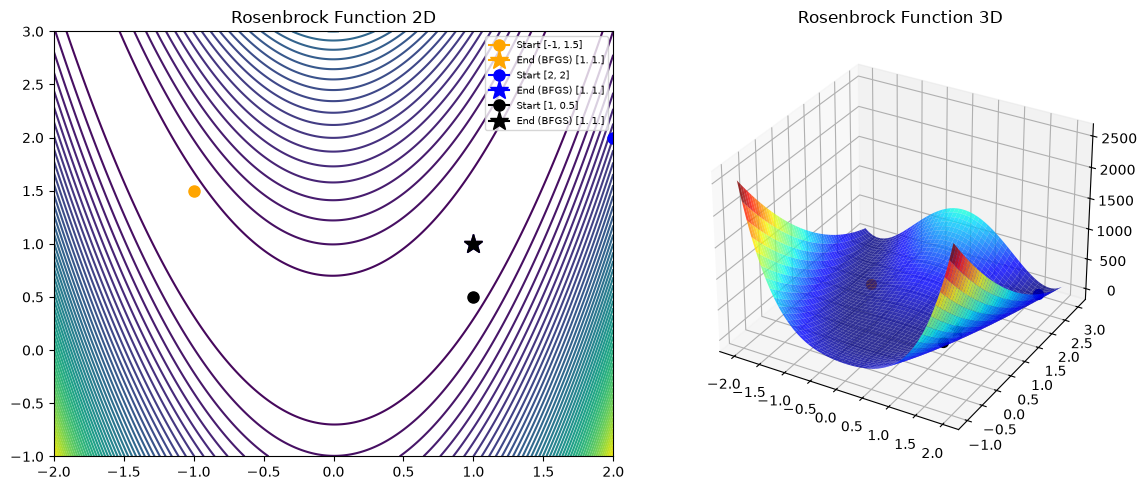

PyGAD initial guess [-1, 1.5], Solution: [0.9550053  0.91219028], Value: 0.0020269303530503456, iterations: 2000, Time: 1.0561 sec
PyGAD initial guess [2, 2], Solution: [1.00328837 1.00617476], Value: 2.7852743296876865e-05, iterations: 2000, Time: 1.1928 sec
PyGAD initial guess [1, 0.5], Solution: [0.97227786 0.94519512], Value: 0.0007701841967394804, iterations: 2000, Time: 1.0868 sec


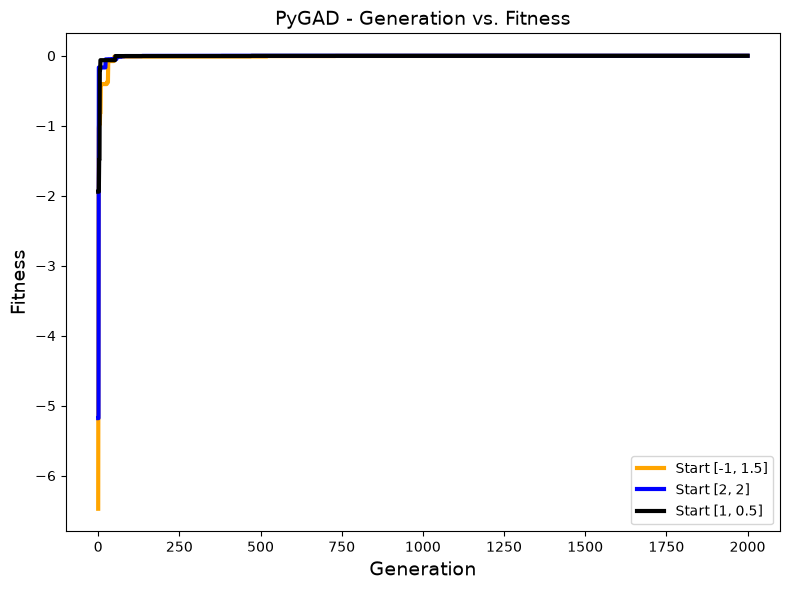

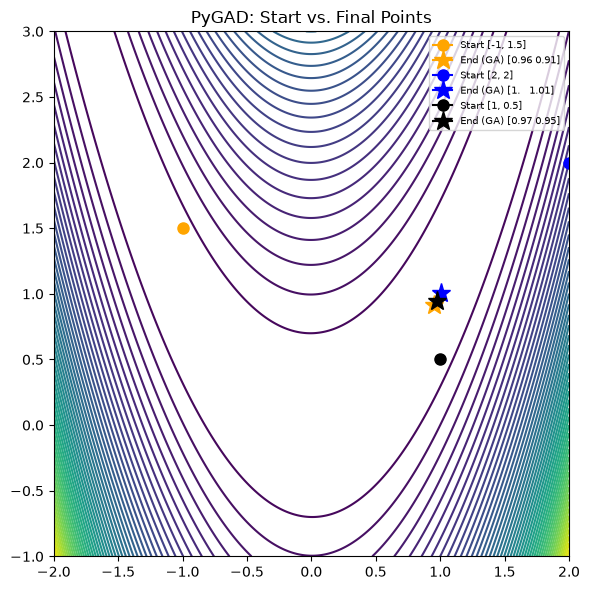

In [21]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")

init_guesses = [[-1, 1.5], [2, 2], [1, 0.5]]
colors = ['orange', 'blue', 'black']

# ------------------- Scipy Optimization -------------------
scipy_results = []  # store (guess, final_point, color) for plotting later

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed:.4f} sec")

    scipy_results.append((guess, result.x, color))

    # Plot initial (marker 'o') and final (marker '*') points on the 2D contour
    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    # Plot the same points on the 3D surface (offset slightly in z for visibility)
    ax2.scatter(guess[0], guess[1], rosenbrock(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], rosenbrock(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)  # pygad maximizes, so negate

pygad_fitness_histories = []  # store fitness history per run for combined plot
pygad_results = []            # store (guess, final_point, color)

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000,
                            sol_per_pop=20,
                            num_genes=2,
                            num_parents_mating=8,
                            fitness_func=fitness_func,
                            init_range_low=-2,
                            init_range_high=2,
                            gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    final_value = rosenbrock(solution)
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {final_value}, "
          f"iterations: {iters}, Time: {elapsed:.4f} sec")

    pygad_results.append((guess, solution, color))

    # best_solutions_fitness holds the best fitness per generation (auto-tracked by pygad)
    # keep it as fitness (not converted to rosenbrock value) to match PyGAD's default plot style
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs, styled like PyGAD's own plot_fitness()
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

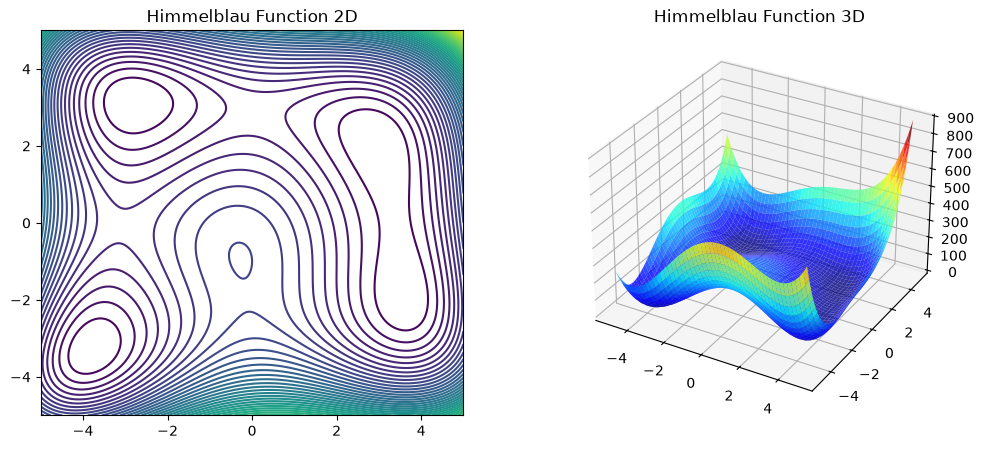

Initial guess [-1, 1], Result: [-2.80511805  3.13131249], Value: 7.13031283866096e-14, Success: True, Iterations: 6
Initial guess [0, 0.5], Result: [2.99999995 2.00000003], Value: 7.73664517139449e-14, Success: True, Iterations: 11
Initial guess [3, 4], Result: [2.99999995 2.00000001], Value: 7.883246228944487e-14, Success: True, Iterations: 9


c:\Users\keert\.conda\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-1, 1], Solution: [3.00198804 2.00137569], Value: 0.0002332410651078586


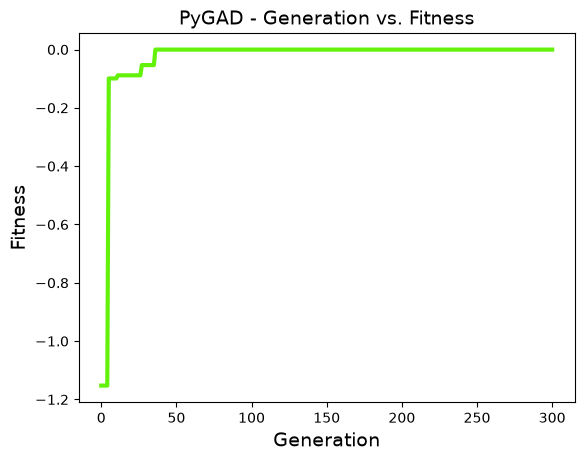

PyGAD initial guess [0, 0.5], Solution: [2.98946259 2.00780543], Value: 0.003489339937100262


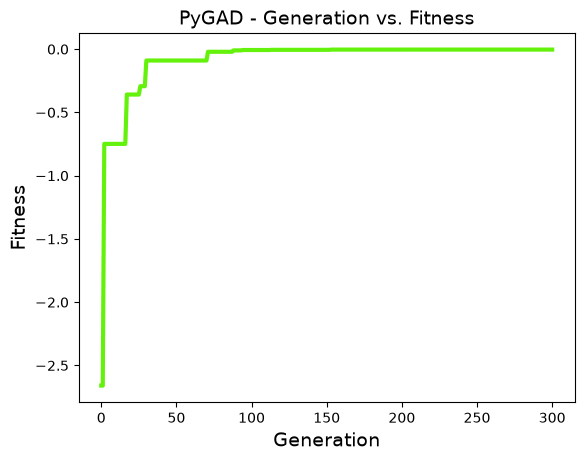

PyGAD initial guess [3, 4], Solution: [3.0122316  1.99068846], Value: 0.004746589343720537


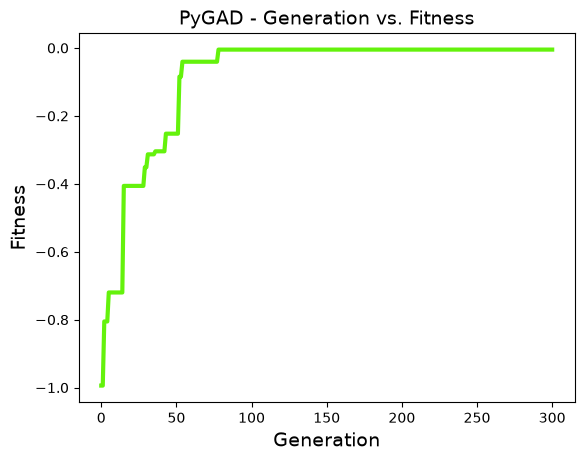

In [26]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
init_guesses = [[-1, 1], [0, 0.5], [3, 4]]
for guess in init_guesses:
    result = minimize(himmelblau, guess, method='BFGS')
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for guess in init_guesses:
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}") # TODO include iterations and time taken
    ga_instance.plot_fitness()

# Optimization of the Given Function

The function to be minimized is f(x,y)=(x^2+y^2-1)^2+(x-1)^2+y^2 with respect to x and y.

## Analytical Solution

For the given function the global minimum is at (1,0) which are stationary points found analytically.
## (1) SciPy Optimization

The `scipy.optimize.minimize()` function with the **BFGS** algorithm was used.

Different initial guesses were tested. For example,(-1, 1), (0, 0.5), (3, 4).

For the tested initial guesses, BFGS converged to approximately x=1, y=0 with f(x,y) approximately 0

The 2D contour plot and 3D surface plot show that the function has its lowest point at (1,0).

**Conclusion:** BFGS finds the global minimum for the tested initial guesses.

(2) Genetic Algorithm using PyGAD

The same function was optimized using `pygad.GA`.

Since PyGAD maximizes the fitness function, the fitness was defined as Fitness=-f(x,y).

Thus, minimizing f(x,y) is equivalent to maximizing the fitness.

Different initial populations/runs were tested. The GA converged approximately to x=1, y=0 with f(x,y) approximately 0

Because the Genetic Algorithm is stochastic, the exact solution and number of generations may vary slightly between runs.

**Conclusion:** The GA also finds the global minimum for the tested runs.

(3) Comparison

Both methods were compared at the same accuracy level, for example **3 decimal places**.

| Parameter       | BFGS           | Genetic Algorithm |
| --------------- | -------------- | ----------------- |
| Final x         | ≈ 1.000        | ≈ 1.000           |
| Final y         | ≈ 0.000        | ≈ 0.000           |
| Objective value | ≈ 0            | ≈ 0               |
| Iterations      | Fewer          | More              |
| Time            | Faster         | Slower            |
| Method          | Gradient-based | Population-based  |
| Stochastic      | No             | Yes               |

Conclusion

Both methods obtained the global minimum: (x,y)=(1,0),f(x,y)=0

For this smooth function, **BFGS is faster and requires fewer iterations**, whereas the **Genetic Algorithm performs a broader stochastic search but generally requires more generations and computational time**.


Initial guess [1, 1], Result: [ 9.99999994e-01 -2.63536186e-09], Value: 2.02512057732456e-16, Success: True, Iterations: 10, Time: 0.0453 sec
Initial guess [0, 0.5], Result: [1.00000002e+00 1.11315806e-08], Value: 2.426495523827813e-15, Success: True, Iterations: 9, Time: 0.0060 sec
Initial guess [3, 4], Result: [ 9.99999996e-01 -8.33027782e-07], Value: 6.940103051875255e-13, Success: True, Iterations: 18, Time: 0.0053 sec


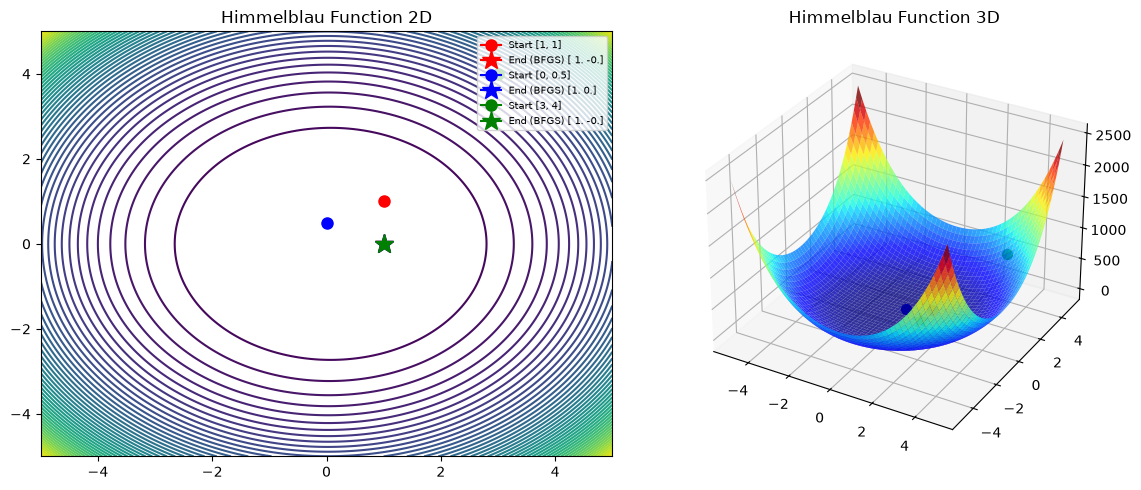

c:\Users\keert\.conda\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [1, 1], Solution: [0.99218714 0.00443849], Value: 0.0003223875675009698, iterations: 300, Time: 0.4697 sec
PyGAD initial guess [0, 0.5], Solution: [0.98404536 0.00297871], Value: 0.0012648836505628918, iterations: 300, Time: 0.4575 sec
PyGAD initial guess [3, 4], Solution: [0.9815309 0.0227688], Value: 0.002161196716052741, iterations: 300, Time: 0.3359 sec


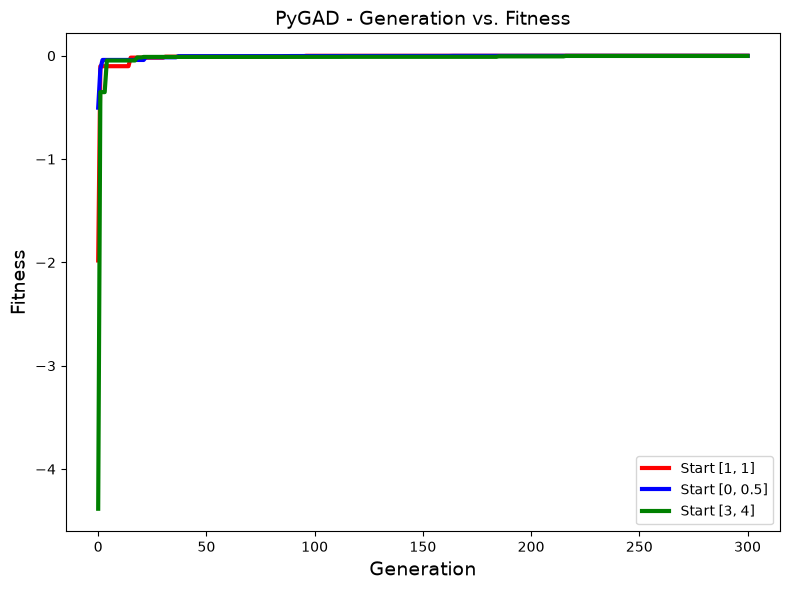

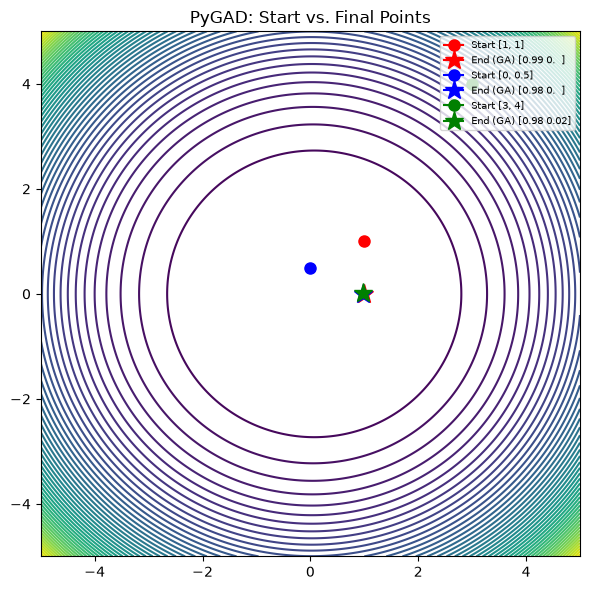

In [29]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

def himmelblau(x):
    x = np.asarray(x)  # Convert to numpy array
    return ((x[0]**2 + x[1]**2 - 1)**2 + (x[0]-1)**2 + x[1]**2)

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")

init_guesses = [[1, 1], [0, 0.5], [3, 4]]
colors = ['red', 'blue', 'green']

# ------------------- Scipy Optimization -------------------
for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = -start_time + end_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

    # Plot initial (marker 'o') and final (marker '*') points on the 2D contour
    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    # Plot the same points on the 3D surface
    ax2.scatter(guess[0], guess[1], himmelblau(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], himmelblau(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

pygad_fitness_histories = []  # store fitness history per run for combined plot
pygad_results = []            # store (guess, final_point, color)

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                            sol_per_pop=30,
                            num_genes=2,
                            num_parents_mating=12,
                            fitness_func=fitness_func2,
                            init_range_low=-5,
                            init_range_high=5,
                            gene_space={'low': -5, 'high': 5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = -start_time + end_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")

    pygad_results.append((guess, solution, color))

    # best_solutions_fitness holds the best fitness per generation (auto-tracked by pygad)
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs, styled like PyGAD's own plot_fitness()
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()